# The Mid-Range Is Dead: Two Key Visualizations

DS 2023 Project 2. Two charts that tell the main story of our dashboard:

1. **Where the shots went:** the share of all NBA shot attempts by court zone, 2004–2024.
2. **Then vs now:** where shots were taken in 2003–04 compared with 2023–24.

Data: every regular-season NBA shot from 2003–04 to 2023–24 ([NBA_Shots_04_25](https://github.com/DomSamangy/NBA_Shots_04_25)). The first run downloads about 75 MB to `data/`.

In [1]:
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Arc, Circle
from matplotlib.colors import LinearSegmentedColormap, PowerNorm

DATA = Path("data")
DATA.mkdir(exist_ok=True)
SEASONS = range(2004, 2025)  # 2004 = the 2003-04 season
BASE = "https://raw.githubusercontent.com/DomSamangy/NBA_Shots_04_25/main"

ZONE_ORDER = ["At the rim", "Paint", "Mid-range", "Corner 3", "Above-break 3"]
ZONE_COLORS = {"At the rim": "#3B6EA5", "Paint": "#86A9CF", "Mid-range": "#A3AAB5",
               "Corner 3": "#E8702A", "Above-break 3": "#F4A36B"}
ZONE_MAP = {"Restricted Area": "At the rim", "In The Paint (Non-RA)": "Paint", "Mid-Range": "Mid-range",
            "Left Corner 3": "Corner 3", "Right Corner 3": "Corner 3", "Above the Break 3": "Above-break 3"}
INK = "#1E2229"
HEAT = LinearSegmentedColormap.from_list("heat", ["#FCE9DC", "#F4A36B", "#E8702A", "#A8400F"])

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})

## Load the data

In [2]:
frames = []
for season in SEASONS:
    path = DATA / f"NBA_{season}_Shots.csv.zip"
    if not path.exists():
        urllib.request.urlretrieve(f"{BASE}/{path.name}", path)
    with zipfile.ZipFile(path) as z:  # each zip also holds a __MACOSX file, so open the CSV by name
        frames.append(pd.read_csv(z.open(f"NBA_{season}_Shots.csv"),
                                  usecols=["SEASON_1", "BASIC_ZONE", "LOC_X", "LOC_Y"]))

shots = pd.concat(frames, ignore_index=True).rename(columns={"SEASON_1": "SEASON"})
shots["ZONE"] = shots["BASIC_ZONE"].map(ZONE_MAP)
shots = shots.dropna(subset=["ZONE"])   # drop backcourt heaves
shots["Y"] = shots["LOC_Y"] - 5.25      # put the hoop at (0, 0)

print(f"{len(shots):,} shots, {shots['SEASON'].min()}-{shots['SEASON'].max()}")
shots.head()

4,222,442 shots, 2004-2024


,SEASON,BASIC_ZONE,LOC_X,LOC_Y,ZONE,Y
0,2004,Above the Break 3,20.0,21.35,Above-break 3,16.1
1,2004,Restricted Area,-0.0,5.25,At the rim,0.0
2,2004,Mid-Range,13.3,24.45,Mid-range,19.2
3,2004,Mid-Range,16.4,13.95,Mid-range,8.7
4,2004,Mid-Range,-15.8,7.85,Mid-range,2.6


## 1. Where the shots went

Each band is one zone's share of all field-goal attempts in that season. The mid-range (gray) shrinks from about a third of all shots to about a tenth, and threes (orange) take its place.

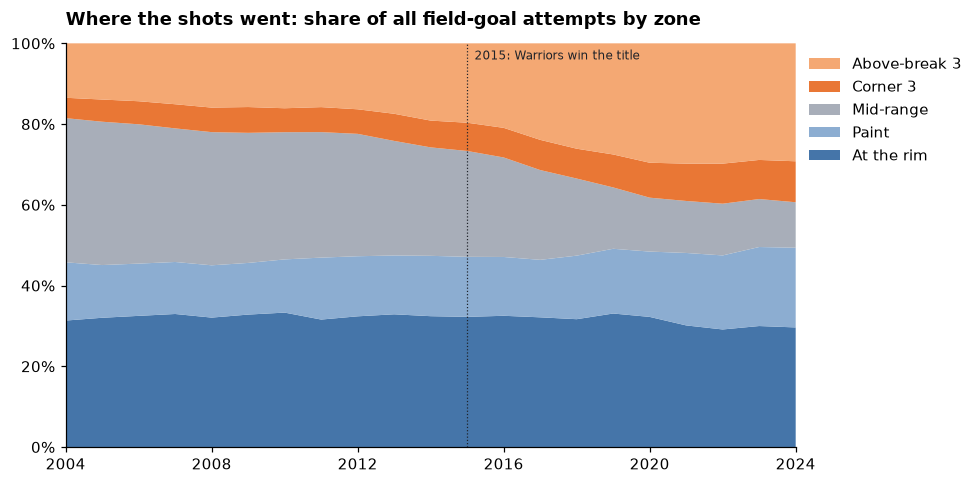

Threes:    19% -> 39% of all shots
Mid-range: 36% -> 11% of all shots


In [3]:
share = (shots.groupby(["SEASON", "ZONE"]).size()
         .unstack()[ZONE_ORDER]
         .pipe(lambda t: t.div(t.sum(axis=1), axis=0)))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.stackplot(share.index, share.T.values, labels=ZONE_ORDER,
             colors=[ZONE_COLORS[z] for z in ZONE_ORDER], alpha=0.95, lw=0)
ax.axvline(2015, color=INK, lw=0.8, ls=":")
ax.text(2015.2, 0.96, "2015: Warriors win the title", fontsize=8, color=INK)
ax.set_xlim(2004, 2024); ax.set_ylim(0, 1)
ax.set_xticks(range(2004, 2025, 4))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.set_title("Where the shots went: share of all field-goal attempts by zone", loc="left", fontweight="bold", pad=12)
ax.legend(loc="upper left", bbox_to_anchor=(1, 1), frameon=False, reverse=True)
plt.tight_layout(); plt.show()

threes = ["Corner 3", "Above-break 3"]
print(f"Threes:    {share.loc[2004, threes].sum():.0%} -> {share.loc[2024, threes].sum():.0%} of all shots")
print(f"Mid-range: {share.loc[2004, 'Mid-range']:.0%} -> {share.loc[2024, 'Mid-range']:.0%} of all shots")

## 2. Then vs now

Every shot from one full season, binned into hexagons (darker = more attempts). In 2003–04 shots are spread across the whole floor. By 2023–24 they cluster at the rim and just behind the three-point line, with a near-empty ring in between.

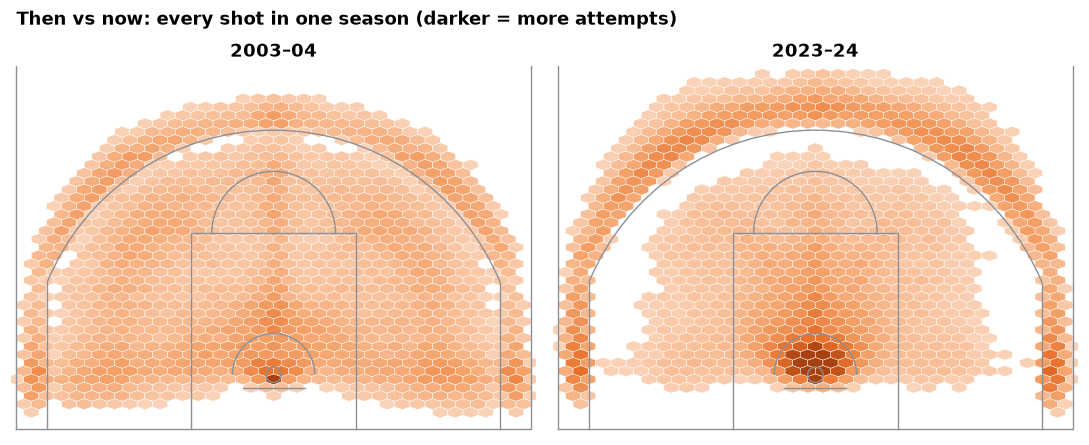

In [4]:
def draw_court(ax, color="#8A8F98", lw=0.9):
    """Half court in feet with the hoop at (0, 0)."""
    kw = dict(color=color, lw=lw, zorder=5)
    ax.plot([-25, 25, 25, -25, -25], [-5.25, -5.25, 41.75, 41.75, -5.25], **kw)
    ax.plot([-8, -8, 8, 8], [-5.25, 13.75, 13.75, -5.25], **kw)
    ax.plot([-3, 3], [-1.25, -1.25], **kw)
    ax.plot([-22, -22], [-5.25, 8.95], **kw)
    ax.plot([22, 22], [-5.25, 8.95], **kw)
    for patch in [Circle((0, 0), 0.75), Arc((0, 13.75), 12, 12, theta1=0, theta2=180),
                  Arc((0, 0), 8, 8, theta1=0, theta2=180), Arc((0, 0), 47.5, 47.5, theta1=22.1, theta2=157.9)]:
        patch.set(fill=False, ec=color, lw=lw, zorder=5)
        ax.add_patch(patch)
    ax.set_xlim(-25.5, 25.5); ax.set_ylim(-5.75, 30)
    ax.set_aspect("equal"); ax.axis("off")


fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, season, label in zip(axes, [2004, 2024], ["2003–04", "2023–24"]):
    s = shots[(shots["SEASON"] == season) & (shots["Y"] < 30)]
    ax.hexbin(s["LOC_X"], s["Y"], gridsize=(34, 22), extent=(-25, 25, -5.25, 30), cmap=HEAT,
              norm=PowerNorm(0.45, vmin=0, vmax=3000), mincnt=20, lw=0.3, edgecolors="white")
    draw_court(ax)
    ax.set_title(label, fontweight="bold")
fig.suptitle("Then vs now: every shot in one season (darker = more attempts)", x=0.02, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()